# ML Final Exam: U.S. County Data

**Source file:** `dataset/elections.csv`

Although the file is called `elections.csv`, it contains U.S. Census county information such as population, income, education, housing, and business statistics. It does not contain an election winner or vote count. Therefore, I use the population-growth percentage (`PST120214`) as the target for a regression problem.

## 0. Dataset overview

I chose this dataset because it has many real-world measurements for U.S. counties. It is useful for seeing how demographic and economic factors are connected with population change.

The target, `PST120214`, is the percentage population change between 2010 and 2014. Predicting a percentage is a regression task because the target can take many numeric values, including decimals and negative values.

# 1. Dataset description (15 marks)

First, I load the data and inspect its size, column types, and missing values. The first rows are national or state totals and do not have a state abbreviation, so I remove them and work only with county-level records.

In [1]:
import os
import warnings

# These settings hide environment-specific warnings that are not related to the analysis.
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
warnings.filterwarnings("ignore", message="Found Intel OpenMP.*")
warnings.filterwarnings("ignore", category=UserWarning,
                        module="joblib.externals.loky.backend.context")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

RANDOM_STATE = 42

raw_df = pd.read_csv("dataset/elections.csv")
df = raw_df[raw_df["state_abbreviation"].notna()].copy()

print("Original shape:", raw_df.shape)
print("County-level shape:", df.shape)
display(df.head())

print("\nData types:")
display(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum()[df.isnull().sum() > 0])

print("\nTarget summary (population growth percentage):")
display(df["PST120214"].describe())

Original shape: (3195, 54)
County-level shape: (3143, 54)


,fips,area_name,state_abbreviation,PST045214,PST040210,PST120214,POP010210,AGE135214,AGE295214,AGE775214,...,SBO415207,SBO015207,MAN450207,WTN220207,RTN130207,RTN131207,AFN120207,BPS030214,LND110210,POP060210
2,1001,Autauga County,AL,55395,54571,1.5,54571,6.0,25.2,13.8,...,0.7,31.7,0,0,598175,12003,88157,131,594.44,91.8
3,1003,Baldwin County,AL,200111,182265,9.8,182265,5.6,22.2,18.7,...,1.3,27.3,1410273,0,2966489,17166,436955,1384,1589.78,114.6
4,1005,Barbour County,AL,26887,27457,-2.1,27457,5.7,21.2,16.5,...,0.0,27.0,0,0,188337,6334,0,8,884.88,31.0
5,1007,Bibb County,AL,22506,22919,-1.8,22915,5.3,21.0,14.8,...,0.0,0.0,0,0,124707,5804,10757,19,622.58,36.8
6,1009,Blount County,AL,57719,57322,0.7,57322,6.1,23.6,17.0,...,0.0,23.2,341544,0,319700,5622,20941,3,644.78,88.9



Data types:


fips                    int64
area_name              object
state_abbreviation     object
PST045214               int64
PST040210               int64
PST120214             float64
POP010210               int64
AGE135214             float64
AGE295214             float64
AGE775214             float64
SEX255214             float64
RHI125214             float64
RHI225214             float64
RHI325214             float64
RHI425214             float64
RHI525214             float64
RHI625214             float64
RHI725214             float64
RHI825214             float64
POP715213             float64
POP645213             float64
POP815213             float64
EDU635213             float64
EDU685213             float64
VET605213               int64
LFE305213             float64
HSG010214               int64
HSG445213             float64
HSG096213             float64
HSG495213               int64
HSD410213               int64
HSD310213             float64
INC910213               int64
INC110213 


Missing values:


Series([], dtype: int64)


Target summary (population growth percentage):


count    3143.000000
mean        0.465670
std         4.190895
min       -17.000000
25%        -2.000000
50%        -0.200000
75%         2.200000
max        72.900000
Name: PST120214, dtype: float64

### Explanation

- The original file has **3,195 rows** and **54 columns**. After removing non-county summary rows, the analysis uses county records only.
- The target is `PST120214`. It is a quantitative, continuous percentage, so this is a **regression** problem.
- Most columns are numeric measurements. `area_name` and `state_abbreviation` are categorical text columns, while `fips` is an identifier.
- `state_abbreviation` is missing only for the summary rows that were removed. The remaining county data has no missing values.
- I do not encode `area_name` or `state_abbreviation`. `area_name` has too many unique values and is mainly an identifier, while state codes could make the model memorize locations instead of learning demographic patterns. The `fips` column is also only an identifier. These columns are dropped.

## Exploratory Data Analysis

A correlation heatmap is useful here because most remaining columns are numeric. It helps find linear relationships. Correlation does not prove causation, and a low correlation does not always mean a feature is useless.

Features most positively related to population growth:


PST120214    1.000000
INC110213    0.450158
EDU685213    0.431071
INC910213    0.378093
HSG495213    0.366944
BPS030214    0.332292
HSG096213    0.318680
POP645213    0.314698
Name: PST120214, dtype: float64

Features most negatively related to population growth:


SEX255214    0.011114
RHI125214   -0.017303
RHI225214   -0.099898
RHI825214   -0.116874
HSG445213   -0.201091
PVY020213   -0.226506
POP715213   -0.271291
AGE775214   -0.414342
Name: PST120214, dtype: float64

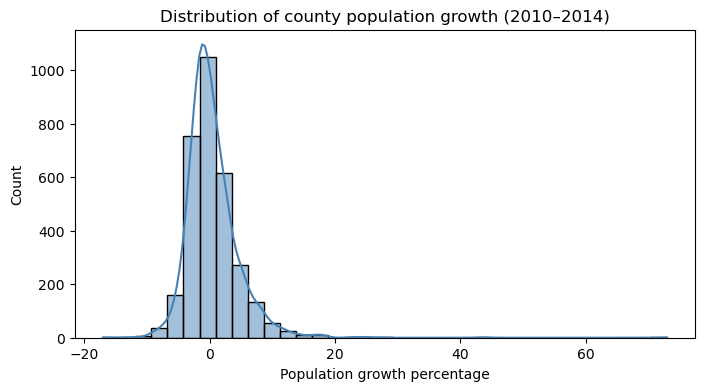

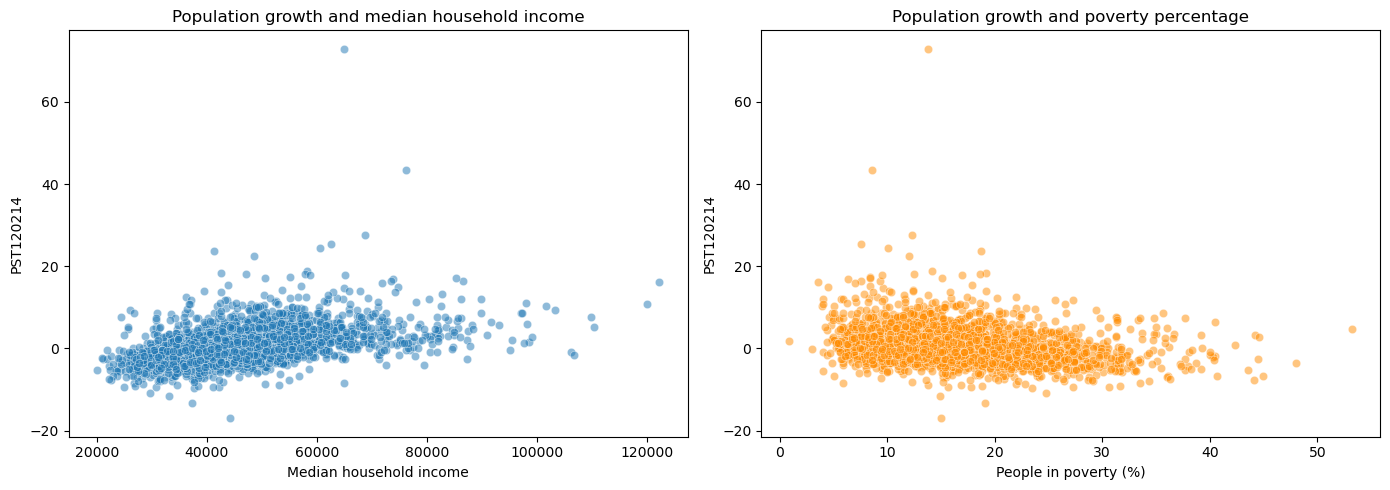

In [2]:
target = "PST120214"

# These population-count columns are directly related to the calculation of the target.
# They are removed to avoid giving the model a shortcut (data leakage).
leakage_columns = ["PST045214", "PST040210", "POP010210"]
identifier_columns = ["fips", "area_name", "state_abbreviation"]
feature_columns = [column for column in df.columns
                   if column not in identifier_columns + leakage_columns + [target]]

model_df = df[feature_columns + [target]].copy()

correlation_with_target = model_df.corr()[target].sort_values(ascending=False)
print("Features most positively related to population growth:")
display(correlation_with_target.head(8))
print("Features most negatively related to population growth:")
display(correlation_with_target.tail(8))

plt.figure(figsize=(8, 4))
sns.histplot(df[target], bins=35, kde=True, color="steelblue")
plt.title("Distribution of county population growth (2010–2014)")
plt.xlabel("Population growth percentage")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x="INC110213", y=target, alpha=0.5, ax=axes[0])
axes[0].set_title("Population growth and median household income")
axes[0].set_xlabel("Median household income")

sns.scatterplot(data=df, x="PVY020213", y=target, alpha=0.5, ax=axes[1], color="darkorange")
axes[1].set_title("Population growth and poverty percentage")
axes[1].set_xlabel("People in poverty (%)")

plt.tight_layout()
plt.show()

### EDA observations

The target distribution shows that many counties have small changes, while a smaller number have much larger growth or decline. The scatter plots help show whether income and poverty have simple linear patterns with population growth. In practice, the relationship is not perfectly linear, so it is useful to compare a linear model with a non-linear model.

I deliberately removed the three population-count columns used in the target's time period. Otherwise, the model could partly reconstruct the growth percentage instead of learning from other county characteristics.

# 2. Dataset pre-processing (15 marks)

Before training, I separate the features from the target. All retained features are numeric. I still use a median imputer so the pipeline can safely handle missing values if new county data is added later.

In [3]:
X = df[feature_columns]
y = df[target]

print("Number of input features:", X.shape[1])
print("Number of counties:", X.shape[0])
print("\nFirst five selected features:", feature_columns[:5])

# The actual preprocessing steps are included inside each model pipeline below.
# This prevents the test set from influencing the values learned during preprocessing.

Number of input features: 47
Number of counties: 3143

First five selected features: ['AGE135214', 'AGE295214', 'AGE775214', 'SEX255214', 'RHI125214']


### Preprocessing explanation

The median imputer is a safe choice for numeric columns because it is less affected by unusual large values than the mean. Scaling is used for Ridge Regression because its coefficients depend on feature size. Random Forest does not need scaling because it splits values using thresholds.

Putting preprocessing inside each pipeline is important: the training data learns the imputation, scaling, and feature-selection steps; the test data is only transformed using those learned steps.

# 3. Feature selection and Dataset splitting (10 marks)

I start with 47 non-identifier, non-leakage numeric features. Then I use `SelectKBest` to keep the 15 features with the strongest individual linear relationship to population growth on the training data. This is a simple, reproducible feature-selection method.

I use an 80/20 train-test split. The test set is not used during training and gives a fair estimate of performance on unseen counties.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)
print("Training target mean:", round(y_train.mean(), 3))
print("Test target mean:", round(y_test.mean(), 3))

Training set shape: (2514, 47)
Test set shape: (629, 47)
Training target mean: 0.506
Test target mean: 0.306


# 4. Pipeline Creation (Supervised) (10 marks)

I chose two regression algorithms for comparison:

1. **Ridge Regression** is a simple linear baseline. It is a good first model because it is fast, easier to explain, and regularization helps when features are correlated.
2. **Random Forest Regressor** combines many decision trees. I chose it because it can learn non-linear relationships and interactions, for example when population growth depends on several demographic conditions together.

Both models include the same imputation and 15-feature selection step, so the comparison is fair.

In [5]:
ridge_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_regression, k=15)),
    ("model", Ridge(alpha=10))
])

forest_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("select", SelectKBest(score_func=f_regression, k=15)),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

print("Both regression pipelines are ready.")

Both regression pipelines are ready.


# 5. Model Training (5 marks)

Now I fit both pipelines using only the training data, then predict population growth for the separate test set.

In [6]:
ridge_pipeline.fit(X_train, y_train)
forest_pipeline.fit(X_train, y_train)

ridge_predictions = ridge_pipeline.predict(X_test)
forest_predictions = forest_pipeline.predict(X_test)

selected_features = X_train.columns[forest_pipeline.named_steps["select"].get_support()].tolist()
print("Selected features used by the model:")
print(selected_features)

Selected features used by the model:
['AGE135214', 'AGE295214', 'AGE775214', 'RHI425214', 'POP715213', 'POP645213', 'EDU685213', 'VET605213', 'HSG096213', 'HSG495213', 'HSD310213', 'INC910213', 'INC110213', 'RTN131207', 'BPS030214']


# 6. Model selection / Comparison analysis (15 marks)

For regression, I use three measures:

- **R² score:** how much of the variation in population growth is explained by the model. Higher is better.
- **MAE (mean absolute error):** average prediction error in percentage points. Lower is better.
- **RMSE (root mean squared error):** like MAE, but it penalizes large mistakes more strongly. Lower is better.

,R2,MAE,RMSE
Model,,,
Ridge Regression,0.431,2.034,3.138
Random Forest,0.595,1.660,2.647


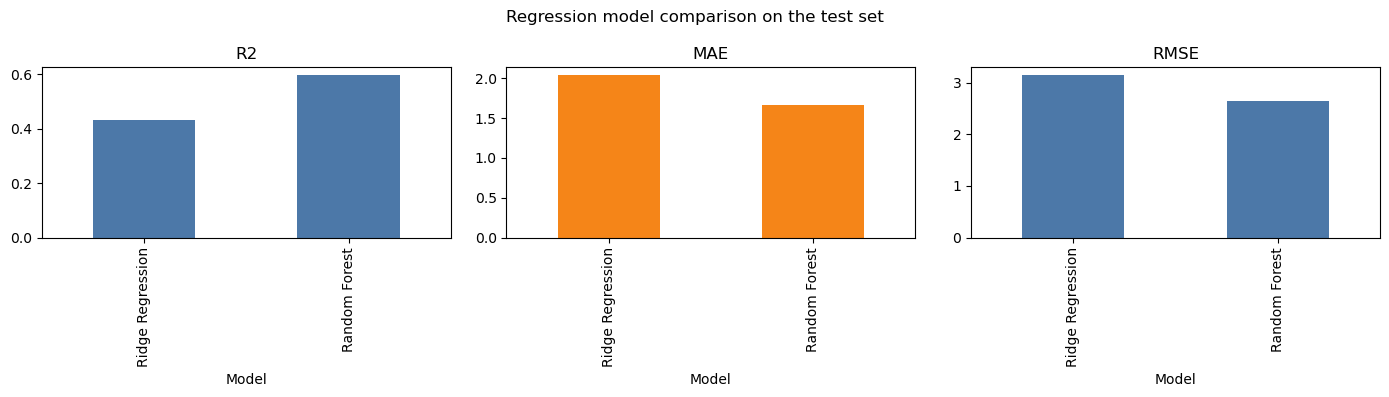

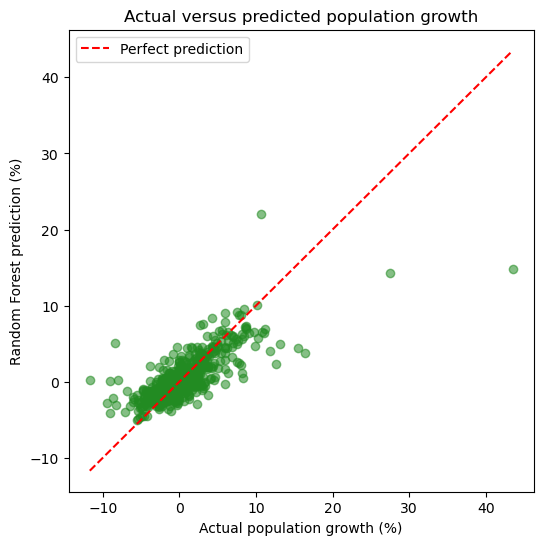

In [7]:
predictions = {
    "Ridge Regression": ridge_predictions,
    "Random Forest": forest_predictions
}

results = []
for name, predicted_values in predictions.items():
    results.append({
        "Model": name,
        "R2": r2_score(y_test, predicted_values),
        "MAE": mean_absolute_error(y_test, predicted_values),
        "RMSE": mean_squared_error(y_test, predicted_values) ** 0.5
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))

results_df.plot(kind="bar", subplots=True, layout=(1, 3), figsize=(14, 4), legend=False,
                color=["#4C78A8", "#F58518"])
plt.suptitle("Regression model comparison on the test set")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 6))
plt.scatter(y_test, forest_predictions, alpha=0.55, color="forestgreen")
line_min = min(y_test.min(), forest_predictions.min())
line_max = max(y_test.max(), forest_predictions.max())
plt.plot([line_min, line_max], [line_min, line_max], "r--", label="Perfect prediction")
plt.xlabel("Actual population growth (%)")
plt.ylabel("Random Forest prediction (%)")
plt.title("Actual versus predicted population growth")
plt.legend()
plt.show()

### Comparison conclusion

The table above should be used to select the better model: the preferred model has a higher R² and lower MAE/RMSE. Random Forest often performs better on this data because county population growth is likely influenced by non-linear combinations of economic, education, housing, and demographic features.

The actual-versus-predicted plot gives another useful check. Points close to the dashed diagonal line are accurate predictions. Large departures from the line are counties where the model made a larger error.

# 7. Treating the problem as Unsupervised (20 marks)

For the unsupervised part, I remove the population-growth target and group counties using only their features.

I use **PCA** first because the data has 47 features, which cannot be drawn directly. PCA reduces these features to two components while preserving as much overall variation as possible. This makes a simple two-dimensional visualisation possible.

Then I use **K-Means** because it is an easy clustering method for numeric, scaled data. It places similar counties in the same group. Instead of choosing the number of clusters randomly, I compare silhouette scores for 2 to 6 clusters and choose the value with the highest score.

  File "C:\Users\User\miniconda3\envs\ai_master\Lib\site-packages\joblib\externals\loky\backend\context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")
C:\Users\User\miniconda3\envs\ai_master\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


Silhouette scores: {2: 0.585, 3: 0.356, 4: 0.236, 5: 0.198, 6: 0.18}
Chosen number of clusters: 2


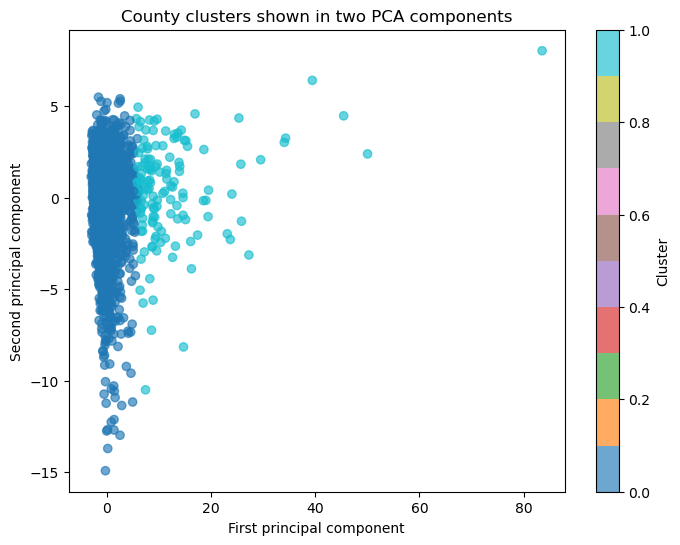

Population growth summary after clustering (not used to create clusters):


,count,mean,median
cluster,,,
0,3005,0.27,-0.40
1,138,4.77,4.35


In [8]:
# For clustering, every feature is scaled so a large-valued feature does not dominate distance.
cluster_imputer = SimpleImputer(strategy="median")
cluster_scaler = StandardScaler()
X_cluster = cluster_imputer.fit_transform(X)
X_cluster = cluster_scaler.fit_transform(X_cluster)

# Choose the number of clusters using silhouette score.
silhouette_scores = {}
for k in range(2, 7):
    labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X_cluster)
    silhouette_scores[k] = silhouette_score(X_cluster, labels)

best_k = max(silhouette_scores, key=silhouette_scores.get)
print("Silhouette scores:", {k: round(score, 3) for k, score in silhouette_scores.items()})
print("Chosen number of clusters:", best_k)

kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X_cluster)

# PCA is used only to make the clusters visible on a two-dimensional plot.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_cluster)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels,
                      cmap="tab10", alpha=0.65)
plt.colorbar(scatter, label="Cluster")
plt.title("County clusters shown in two PCA components")
plt.xlabel("First principal component")
plt.ylabel("Second principal component")
plt.show()

cluster_summary = pd.DataFrame({"cluster": cluster_labels, "population_growth": y}) \
    .groupby("cluster")["population_growth"].agg(["count", "mean", "median"]).round(2)
print("Population growth summary after clustering (not used to create clusters):")
display(cluster_summary)

### Unsupervised conclusion

The silhouette score estimates how well-separated the clusters are; higher is better. K-Means groups counties by overall similarity, not by population growth, because it never sees the target column during training. The final table is only an after-training inspection of how population-growth values differ across clusters.

For predicting population growth, the supervised approach is more suitable because it learns from known growth values. The unsupervised approach is still useful when labels are unavailable or when we want to discover groups of similar counties for policy, marketing, or regional analysis.

# 8. Self Reflection on this machine learning course (10 marks)

The easiest topic for me was the train-test split. It feels similar to studying with practice questions and then taking a separate exam. A model should be tested on data it did not see during training, otherwise we cannot tell whether it learned a useful pattern or simply remembered the examples.

The hardest topic was model evaluation and model choice. A result is not good just because one number looks high. For this regression problem, R², MAE, and RMSE each tell a slightly different story. I also learned that preprocessing and feature selection must be fitted only on training data. Doing them before splitting would allow information from the test set to leak into training and would make the result look better than it really is.